# 03 · Optimización y comparación honesta (Producto 2)
En el Producto 1 la regresión logística empató con los ensambles. Ahora **optimizamos el gradient boosting** (`HistGradientBoostingClassifier`, de la misma familia que LightGBM) y comprobamos **fold a fold** si logra superarla.

Si `optuna` está instalado (en Colab: `!pip install -q optuna`) se usa la búsqueda bayesiana TPE; si no, se usa una búsqueda aleatoria sobre el mismo espacio y con el mismo número de intentos.

In [1]:
# !pip install -q optuna   # (opcional) descomentar en Colab para usar Optuna

import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Datos: EPEN 2025 (INEI), departamento de Puno. El archivo está en data/ del repositorio.
NOMBRE = "21_Puno_EPEN_Anual_2025.csv"
RUTA = next((r for r in [f"../data/{NOMBRE}", f"data/{NOMBRE}", NOMBRE] if Path(r).exists()),
            "https://raw.githubusercontent.com/[USUARIO]/[REPOSITORIO]/main/data/" + NOMBRE)  # <- reemplazar

NUMERICAS = ["edad", "horas_semana", "ingreso_log", "n_limitaciones", "anios_estudio"]
CATEGORICAS = ["sexo", "area", "educacion", "lengua", "etnia", "ocupacion", "rama", "quiere_mas_horas"]

EDUC = {1: "Sin nivel/inicial", 2: "Sin nivel/inicial", 3: "Primaria incompleta", 4: "Primaria completa",
        5: "Secundaria incompleta", 6: "Secundaria completa", 7: "Sin nivel/inicial",
        8: "Superior no univ. incompleta", 9: "Superior no univ. completa",
        10: "Superior univ. incompleta", 11: "Superior univ. completa", 12: "Posgrado"}
ANIOS = {1: 0, 2: 0, 3: 3, 4: 6, 5: 8, 6: 11, 7: 0, 8: 12, 9: 14, 10: 13, 11: 16, 12: 18}  # años de estudio aprox.
OCUP = {0: "Fuerzas armadas", 1: "Directivos", 2: "Profesionales", 3: "Técnicos", 4: "Empleados de oficina",
        5: "Servicios y vendedores", 6: "Agricultores y pecuarios", 7: "Oficiales y artesanos",
        8: "Operadores de maquinaria", 9: "Ocupaciones elementales"}      # CIUO-08, gran grupo

def rama_ciiu(codigo):
    """Agrupa la división CIIU (4 dígitos, sin el cero inicial) en grandes ramas."""
    d = int(codigo) // 100
    if d <= 3:  return "Agricultura y pesca"
    if d <= 9:  return "Minería"
    if d <= 33: return "Manufactura"
    if d <= 39: return "Electricidad y agua"
    if d <= 43: return "Construcción"
    if d <= 47: return "Comercio"
    if d <= 53: return "Transporte"
    if d <= 56: return "Alojamiento y comidas"
    if d <= 82: return "Servicios a empresas"
    if d == 84: return "Administración pública"
    if d == 85: return "Educación"
    if d <= 88: return "Salud"
    return "Otros servicios y hogares"

def cargar_datos():
    raw = pd.read_csv(RUTA)
    # Población de estudio: personas OCUPADAS (OCUP300 = 1) con el indicador de informalidad del INEI
    d = raw[(raw["OCUP300"] == 1) & raw["Informal_P"].notna()].copy()
    out = pd.DataFrame({
        "edad": d["C208"], "horas_semana": d["whoraT"], "ingreso_log": np.log1p(d["INGTOTP"]),
        "n_limitaciones": (d[[f"C375_{i}" for i in range(1, 7)]] == 1).sum(axis=1),
        "anios_estudio": d["C366"].map(ANIOS),
        "sexo": d["C207"].map({1: "Hombre", 2: "Mujer"}),
        "area": d["AREA"].map({1: "Urbano", 2: "Rural"}),
        "educacion": d["C366"].map(EDUC),
        "lengua": d["C376"].map({1: "Quechua", 2: "Aimara", 10: "Castellano"}).fillna("Otra"),
        "etnia": d["C377"].map({1: "Quechua", 2: "Aimara", 6: "Blanco", 7: "Mestizo"}).fillna("Otra/No sabe"),
        "ocupacion": (d["C308_COD"] // 1000).map(OCUP),
        "rama": d["C309_COD"].map(rama_ciiu),
        "quiere_mas_horas": d["C333"].map({1: "Sí", 2: "No"}).fillna("No"),
        "informal": (d["Informal_P"] == 1).astype(int),     # 1 = empleo informal, 2 = formal (ver data/README.md)
        "grupo": d["LLAVE_PANEL"].astype(str),               # identifica a la persona (el panel la repite)
        "ingreso": d["INGTOTP"]})
    return out.reset_index(drop=True)

df = cargar_datos()
X, y, grupos = df[NUMERICAS + CATEGORICAS], df["informal"], df["grupo"]
print(df.shape, f"| empleo informal: {y.mean():.1%} | personas distintas: {grupos.nunique()}")

(7836, 16) | empleo informal: 77.8% | personas distintas: 5479


In [2]:
from sklearn.model_selection import StratifiedGroupKFold, cross_validate, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Misma división en todos los notebooks: 80 % entrenamiento / 20 % test, sin repartir a una persona entre ambos
idx_tr, idx_te = next(StratifiedGroupKFold(5, shuffle=True, random_state=42).split(X, y, grupos))
X_tr, X_te, y_tr, y_te = X.iloc[idx_tr], X.iloc[idx_te], y.iloc[idx_tr], y.iloc[idx_te]
g_tr = grupos.iloc[idx_tr]
cv = StratifiedGroupKFold(5, shuffle=True, random_state=42)   # validación cruzada por persona

def preprocesador():
    num = Pipeline([("imputar", SimpleImputer(strategy="median")), ("escalar", StandardScaler())])
    cat = Pipeline([("imputar", SimpleImputer(strategy="most_frequent")),
                    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
    return ColumnTransformer([("num", num, NUMERICAS), ("cat", cat, CATEGORICAS)])

print(f"entrenamiento: {len(X_tr)} filas · test: {len(X_te)} filas · personas compartidas: {len(set(g_tr) & set(grupos.iloc[idx_te]))}")

entrenamiento: 6269 filas · test: 1567 filas · personas compartidas: 0


## Búsqueda de hiperparámetros (30 intentos, ROC-AUC con validación cruzada por persona)

In [3]:
from sklearn.ensemble import HistGradientBoostingClassifier

def modelo_hgb(**p):
    return Pipeline([("prep", preprocesador()),
                     ("modelo", HistGradientBoostingClassifier(class_weight="balanced", random_state=42, **p))])

def evaluar(p):
    return cross_val_score(modelo_hgb(**p), X_tr, y_tr, cv=cv, groups=g_tr, scoring="roc_auc").mean()

def proponer(sug):
    """Espacio de búsqueda; `sug` entrega enteros/reales según el método (Optuna o aleatorio)."""
    return dict(max_iter=sug.int("max_iter", 100, 500),
                learning_rate=sug.float("learning_rate", 0.01, 0.3, log=True),
                max_leaf_nodes=sug.int("max_leaf_nodes", 8, 64),
                min_samples_leaf=sug.int("min_samples_leaf", 10, 100),
                l2_regularization=sug.float("l2_regularization", 1e-3, 10, log=True),
                max_features=sug.float("max_features", 0.5, 1.0))

try:
    import optuna
    optuna.logging.set_verbosity(optuna.logging.WARNING)
    class _Sug:                       # adaptador para un trial de Optuna
        def __init__(s, t): s.t = t
        def int(s, n, a, b): return s.t.suggest_int(n, a, b)
        def float(s, n, a, b, log=False): return s.t.suggest_float(n, a, b, log=log)
    estudio = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=42))
    estudio.optimize(lambda t: evaluar(proponer(_Sug(t))), n_trials=30)
    mejores, mejor_valor, metodo = estudio.best_params, estudio.best_value, "Optuna (TPE)"
except ImportError:
    class _Sug:                       # búsqueda aleatoria con la misma interfaz
        def __init__(s, rng): s.r = rng
        def int(s, n, a, b): return int(s.r.integers(a, b + 1))
        def float(s, n, a, b, log=False):
            return float(np.exp(s.r.uniform(np.log(a), np.log(b)))) if log else float(s.r.uniform(a, b))
    rng = np.random.default_rng(42)
    intentos = [proponer(_Sug(rng)) for _ in range(30)]
    valores = [evaluar(p) for p in intentos]
    mejores, mejor_valor, metodo = intentos[int(np.argmax(valores))], max(valores), "búsqueda aleatoria"
print(f"Método: {metodo}")
print(f"Mejor ROC-AUC (CV): {mejor_valor:.4f}")
print("Mejores hiperparámetros:", {k: (round(v, 4) if isinstance(v, float) else v) for k, v in mejores.items()})

Método: búsqueda aleatoria
Mejor ROC-AUC (CV): 0.9513
Mejores hiperparámetros: {'max_iter': 284, 'learning_rate': 0.0148, 'max_leaf_nodes': 33, 'min_samples_leaf': 70, 'l2_regularization': 0.0766, 'max_features': 0.7826}


## ¿La mejora es real? Comparación fold a fold (5 folds × 5 repeticiones, por persona)

In [4]:
from sklearn.linear_model import LogisticRegression
from scipy.stats import wilcoxon

def cv_repetido(modelo, repeticiones=5):
    """25 puntajes; los tres modelos usan exactamente los mismos folds (comparación pareada)."""
    puntajes = []
    for r in range(repeticiones):
        cv_r = StratifiedGroupKFold(5, shuffle=True, random_state=r)
        puntajes += list(cross_val_score(modelo, X_tr, y_tr, cv=cv_r, groups=g_tr, scoring="roc_auc"))
    return np.array(puntajes)

a = cv_repetido(modelo_hgb(**mejores))
b = cv_repetido(modelo_hgb())
c = cv_repetido(Pipeline([("prep", preprocesador()),
                          ("modelo", LogisticRegression(max_iter=1000, class_weight="balanced"))]))
print(f"Boosting optimizado:  {a.mean():.4f} ± {a.std():.4f}")
print(f"Boosting original:    {b.mean():.4f} ± {b.std():.4f}")
print(f"Regresión logística:  {c.mean():.4f} ± {c.std():.4f}")
for nombre, otro in [("boosting original", b), ("regresión logística", c)]:
    dif = a - otro
    print(f"Optimizado vs. {nombre}: gana en {(dif > 0).sum()} de {len(dif)} folds · "
          f"diferencia media = {dif.mean():+.4f} · Wilcoxon p = {wilcoxon(dif).pvalue:.2g}")

Boosting optimizado:  0.9512 ± 0.0062
Boosting original:    0.9468 ± 0.0064
Regresión logística:  0.9472 ± 0.0073
Optimizado vs. boosting original: gana en 25 de 25 folds · diferencia media = +0.0044 · Wilcoxon p = 6e-08
Optimizado vs. regresión logística: gana en 24 de 25 folds · diferencia media = +0.0040 · Wilcoxon p = 3.3e-06


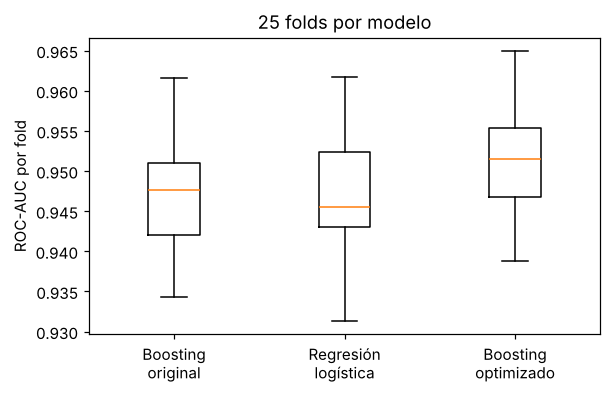

In [5]:
plt.figure(figsize=(6, 3.5))
plt.boxplot([b, c, a]); plt.xticks([1, 2, 3], ["Boosting\noriginal", "Regresión\nlogística", "Boosting\noptimizado"])
plt.ylabel("ROC-AUC por fold"); plt.title("25 folds por modelo"); plt.show()

**Conclusión:**
- La optimización **sí funciona**: el boosting optimizado le gana a su versión original en los 25 folds (Wilcoxon p < 0,001; +0,004 de ROC-AUC).
- También **supera a la regresión logística**: gana en 24 de 25 folds (p < 0,001). Pero la diferencia es **pequeña** (0,951 contra 0,947 de ROC-AUC). Como los 25 folds comparten datos entre sí, el valor p exagera la evidencia, así que lo leemos como una **mejora consistente pero modesta**, no como un salto.
- **Decisión:** el modelo final es el **boosting optimizado**: gana de forma consistente y no complica la demo. Conservamos la regresión logística como referencia simple e interpretable.
- Los hiperparámetros ganadores se copian al notebook 05 (con Optuna pueden salir valores distintos; si cambian, actualícenlos allí).